# Семинар: подготовка данных и линейная регрессия

**План занятия:** разбиение → графики → baseline → медиана → масштабирование →
категории → новый признак → выводы.

На каждом шаге: **выдвигаем гипотезу → меняем данные → обучаем модель →
смотрим RMSE и MAE → делаем вывод**.
Во всех экспериментах обучаем линейную регрессию (`LinearRegression`).
Обучение и предсказание каждый раз записаны явно в короткой ячейке.

Сохраните полный набор `data/ames.csv` в папку `data` рядом с ноутбуком.
В начале разделим его на train, validation и test.
Медианы, масштабирование и список категорий получаем только по train.

Графики и обучение уже написаны. В трёх коротких ячейках с TODO
допишите заполнение пропусков, one-hot и формулу нового признака.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from IPython.display import display

np.random.seed(42)

### 1. Что мы будем предсказывать?

В **Ames Housing** одна строка — один дом. Target `sale_price` — цена продажи.
**MAE** — средний размер ошибки в долларах; **RMSE** сильнее реагирует на большие
промахи. Для обеих метрик меньше — лучше.

<details>
<summary>Словарь признаков — можно посмотреть по ходу занятия</summary>

| Признак | Смысл |
|---|---|
| `lot_frontage`, `lot_area` | Длина границы участка вдоль улицы и площадь участка |
| `gr_liv_area` | Жилая площадь над землёй |
| `total_bsmt_sf`, `1st_flr_sf` | Площадь подвала и первого этажа |
| `garage_area`, `garage_cars` | Площадь гаража и вместимость в автомобилях |
| `overall_qual` | Оценка качества материалов и отделки, 1–10 |
| `year_built`, `yr_sold` | Год постройки и год продажи |
| `neighborhood` | Район города |
| `alley` | Доступ к переулку; пропуск означает отсутствие переулка |
| `bsmt_qual` | Качество подвала; пропуск означает отсутствие подвала |
| `exter_qual`, `kitchen_qual` | Качество внешней отделки и кухни |

Площади измеряются в квадратных футах, длины — в футах.
Шкала категорий качества: `Po < Fa < TA < Gd < Ex`.
В `gr_liv_area` и `garage_area` дополнительно скрыто по 5% известных значений.

</details>

In [30]:
ames = pd.read_csv('data/ames.csv')
ames.shape

(2930, 16)

### Разделим данные на train, validation и test

- **Train** — изучаем данные, считаем статистики и обучаем модель.
- **Validation** — сравниваем варианты подготовки и моделей.
- **Test** — откладываем для финальной проверки; в экспериментах его не используем.

Сначала отделяем 20% на test, затем 20% оставшихся данных — на validation.
Получится примерно 64% / 16% / 20%. `random_state=42` фиксирует разбиение.

In [31]:
ames_train_valid, ames_test = train_test_split(
    ames, test_size=0.2, random_state=42
)
ames_train, ames_valid = train_test_split(
    ames_train_valid, test_size=0.2, random_state=42
)
pd.Series({'train': len(ames_train), 'validation': len(ames_valid),
           'test': len(ames_test)})

train         1875
validation     469
test           586
dtype: int64

In [32]:
X_ames, y_ames = ames_train.drop(columns='sale_price'), ames_train['sale_price']
X_ames_valid, y_ames_valid = ames_valid.drop(columns='sale_price'), ames_valid['sale_price']
X_ames_test, y_ames_test = ames_test.drop(columns='sale_price'), ames_test['sale_price']
ames_train.head()

,lot_frontage,lot_area,overall_qual,year_built,yr_sold,gr_liv_area,total_bsmt_sf,garage_area,garage_cars,1st_flr_sf,neighborhood,alley,exter_qual,kitchen_qual,bsmt_qual,sale_price
2831,24.0,2522,7,2004,2006,1709.0,970.0,380.0,2.0,970,Edwards,NaN,Gd,Gd,Gd,137500
2735,NaN,19690,6,1966,2006,2201.0,697.0,432.0,2.0,1575,Edwards,NaN,Gd,Gd,Gd,274970
2134,97.0,11800,5,1974,2007,894.0,864.0,440.0,2.0,894,CollgCr,NaN,TA,TA,Gd,131000
2423,NaN,3072,7,2004,2006,1414.0,1375.0,398.0,2.0,1414,Blmngtn,NaN,Gd,Gd,Gd,178740
1966,80.0,8000,5,1960,2007,1377.0,1377.0,NaN,1.0,1377,NAmes,NaN,TA,TA,TA,156500


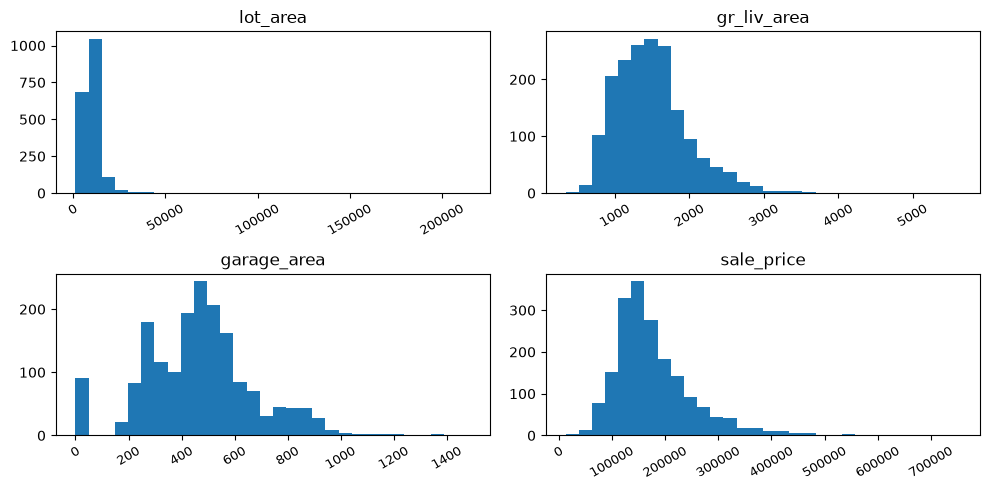

In [33]:
ames_train[['lot_area', 'gr_liv_area', 'garage_area', 'sale_price']].hist(
    bins=30, figsize=(10, 5), grid=False, xrot=30, xlabelsize=9
)
plt.tight_layout()
plt.show()

**Обсудим:** у каких распределений длинный хвост? Почему для заполнения
неизвестной площади медиана может оказаться удачнее среднего?

**Наше наблюдение:** ...

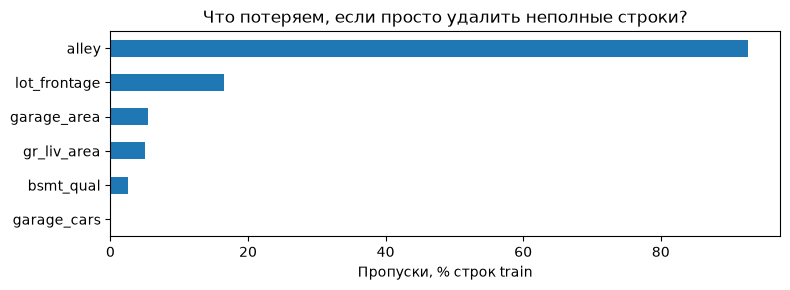

In [34]:
missing_share = X_ames.isna().mean()
(100 * missing_share[missing_share > 0]).sort_values().plot.barh(figsize=(8, 3))
plt.xlabel('Пропуски, % строк train')
plt.title('Что потеряем, если просто удалить неполные строки?')
plt.tight_layout()
plt.show()

**Обсудим:** почему пропуски в `alley` и `gr_liv_area` нельзя обрабатывать
одинаково? Ответ есть в словаре признаков.

**Наше наблюдение:** ...

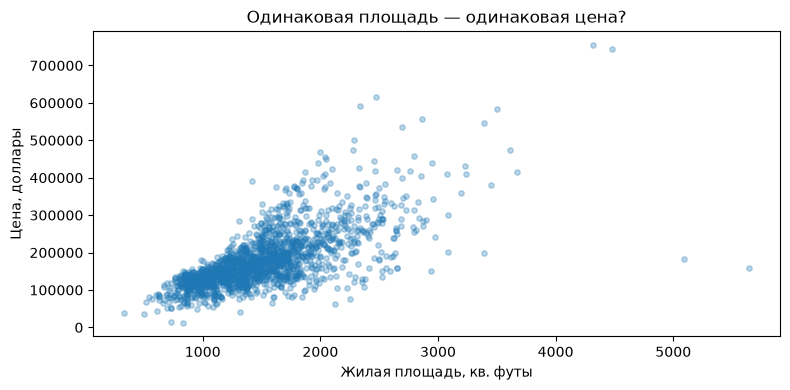

In [35]:
ames_train.plot.scatter(x='gr_liv_area', y='sale_price', alpha=0.3, s=15, figsize=(8, 4))
plt.xlabel('Жилая площадь, кв. футы')
plt.ylabel('Цена, доллары')
plt.title('Одинаковая площадь — одинаковая цена?')
plt.tight_layout()
plt.show()

**Обсудим:** растёт ли цена с площадью? Почему дома одинаковой площади
могут стоить по-разному? Назовите ещё один признак, который стоит добавить.

**Наша гипотеза:** ...

### Матрица корреляций

Сравним пять числовых колонок, включая цену.
Корреляция близка к 1 — значения обычно растут вместе; к −1 — меняются в противоположные стороны.
Около 0 — слабая линейная связь. Пары с пропусками не учитываются.

In [36]:
import seaborn as sns

<Axes: >

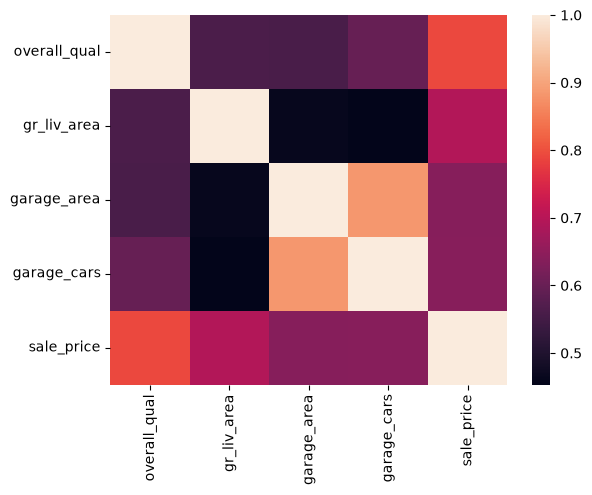

In [37]:
corr_columns = ['overall_qual', 'gr_liv_area', 'garage_area', 'garage_cars', 'sale_price']
sns.heatmap(ames_train[corr_columns].corr())

**Обсудим:** какие признаки сильнее связаны с ценой?
Какие признаки несут похожую информацию?
Почему слабая линейная связь не означает, что признак бесполезен?

**Наш вывод:** ...

### 2. Получим точку отсчёта

Берём только числа и удаляем из train строки с числовыми пропусками.
Один раз фиксируем validation без таких пропусков. **Во всех следующих
экспериментах оцениваемся на этих же домах**, даже после заполнения пропусков.
Оценка будет относиться именно к этой части validation.

Сначала подготовим данные. Посмотрите, сколько обучающих домов осталось.

In [38]:
numeric_columns = X_ames.select_dtypes('number').columns.tolist()
train_complete = X_ames[numeric_columns].dropna()
valid_complete = X_ames_valid[numeric_columns].notna().all(axis=1)
X_ames_eval = X_ames_valid.loc[valid_complete].copy()
y_ames_eval = y_ames_valid.loc[valid_complete]
valid_numeric = X_ames_eval[numeric_columns]
pd.Series({'train до удаления': len(X_ames), 'train после': len(train_complete),
           'validation для всех сравнений': len(X_ames_eval)})

train до удаления                1875
train после                      1397
validation для всех сравнений     354
dtype: int64

**Обучаем модель, получаем предсказания, затем смотрим ошибки.**

In [39]:
baseline_model = LinearRegression()
baseline_model.fit(train_complete, y_ames_eval.loc[train_complete.index])
baseline_prediction = baseline_model.predict(valid_numeric)

KeyError: "None of [Index([2831, 2134,   77, 1204, 1728, 2865, 1160,  429,  661, 2020,\n       ...\n       1733,  320,  654, 1653, 1517, 1768,  236, 1546, 1854, 2835],\n      dtype='int64', length=1397)] are in the [index]"

In [ ]:
baseline_metrics = pd.Series({
    'RMSE': mean_squared_error(y_ames_eval, baseline_prediction) ** 0.5,
    'MAE': mean_absolute_error(y_ames_eval, baseline_prediction),
})
baseline_metrics

Какую проблему текущей подготовки данных исправим первой?

### 3. Вернём потерянные обучающие строки

**Гипотеза:** заполнение числовых пропусков позволит использовать больше train
и может уменьшить ошибку.

Замените `None` на `X_ames[numeric_columns].median().fillna(0)`.
Медианы считаем только по train; полностью пустая колонка получила бы 0.
Категории пока не добавляем.

In [ ]:
fill_values = None  # TODO: медианы числовых колонок train.
train_numeric = X_ames[numeric_columns].fillna(fill_values)
valid_numeric = X_ames_eval[numeric_columns].fillna(fill_values)
pd.Series({'train после заполнения': len(train_numeric), 'validation': len(valid_numeric)})

**Изменили только обработку числовых пропусков. Обучим модель заново.**

In [ ]:
median_model = LinearRegression()
median_model.fit(train_numeric, y_ames.loc[train_numeric.index])
median_prediction = median_model.predict(valid_numeric)

In [ ]:
median_metrics = pd.Series({
    'RMSE': mean_squared_error(y_ames_eval, median_prediction) ** 0.5,
    'MAE': mean_absolute_error(y_ames_eval, median_prediction),
})
median_metrics

### 4. Поможет ли масштабирование?

**Сначала предположите результат:** что изменится, если выразить площадь
в другом масштабе? Возьмём заполненные числовые таблицы из прошлого шага
и применим `StandardScaler`. Других изменений не делаем.

In [ ]:
# примените StandardScaler к train_numeric и valid_numeric
scaler = None
train_scaled = None
valid_scaled = None

In [ ]:
scaled_model = LinearRegression()
scaled_model.fit(train_scaled, y_ames.loc[train_scaled.index])
scaled_prediction = scaled_model.predict(valid_scaled)

In [ ]:
scaled_metrics = pd.Series({
    'RMSE': mean_squared_error(y_ames_eval, scaled_prediction) ** 0.5,
    'MAE': mean_absolute_error(y_ames_eval, scaled_prediction),
})
scaled_metrics

**Обсудим:** сравните ошибки с вариантом «медиана». Почему результат почти тот же?



### 5. Добавим информацию о категориях

Пока модель не знает район дома и категориальные оценки качества.
Посмотрим на медианные цены в восьми самых частых районах train.

In [ ]:
common_neighborhoods = X_ames['neighborhood'].value_counts().head(8).index
neighborhood_prices = ames_train.groupby('neighborhood')['sale_price'].median()
neighborhood_prices.loc[common_neighborhoods].sort_values().plot.barh(figsize=(8, 3))
plt.xlabel('Медианная цена, доллары')
plt.title('Восемь самых частых районов train')
plt.tight_layout()
plt.show()

**Обсудим:** отличаются ли цены районов? Доказывает ли это, что причина именно
в районе, а не в площади и качестве домов?

**Наша гипотеза о добавлении категорий:** ...

Сначала заполним пропуски. Для `alley` и `bsmt_qual` явно обозначим отсутствие
объекта, в остальных колонках — неизвестное значение.

In [ ]:
category_columns = X_ames.select_dtypes(exclude='number').columns.tolist()
absence_values = {'alley': 'NoAlley', 'bsmt_qual': 'NoBasement'}
train_categories = X_ames[category_columns].fillna(absence_values).fillna('__MISSING__')
valid_categories = X_ames_eval[category_columns].fillna(absence_values).fillna('__MISSING__')

**Зафиксируем категории по train.** Это нужно, чтобы one-hot создавал одинаковые
колонки и использовал одну и ту же опорную категорию.

In [ ]:
for col in category_columns:
    levels = train_categories[col].unique()
    train_categories[col] = pd.Categorical(train_categories[col], categories=levels)
    valid_categories[col] = pd.Categorical(valid_categories[col], categories=levels)

**Закодируем категории.** Вместо каждого `None` вызовите
`pd.get_dummies` для соответствующей таблицы с `drop_first=True, dtype=float`.
Первая категория будет опорной: её отдельную колонку не добавляем.
Новая категория validation, отсутствующая в train, получит нули.

In [ ]:
train_codes = None  # TODO: pd.get_dummies для train_categories.
valid_codes = None  # TODO: pd.get_dummies для valid_categories.
valid_codes = valid_codes.reindex(columns=train_codes.columns, fill_value=0)

**Добавим категории к прежним числам.** Числовые пропуски по-прежнему заполнены
теми же медианами. Проверяем эффект добавления категориальной информации.

In [ ]:
train_with_categories = pd.concat([train_numeric, train_codes], axis=1)
valid_with_categories = pd.concat([valid_numeric, valid_codes], axis=1)

In [ ]:
categorical_model = LinearRegression()
categorical_model.fit(train_with_categories, y_ames.loc[train_with_categories.index])
categorical_prediction = categorical_model.predict(valid_with_categories)

In [ ]:
categorical_metrics = pd.Series({
    'RMSE': mean_squared_error(y_ames_eval, categorical_prediction) ** 0.5,
    'MAE': mean_absolute_error(y_ames_eval, categorical_prediction),
})
categorical_metrics

**Обсудим:** что изменилось относительно варианта с медианой?
Помогли ли категории по обеим метрикам?

**Наш вывод:** ...

### 6. Придумаем один новый признак

Посмотрим, как цена связана с качеством материалов и отделки.
В boxplot линия — медиана, коробка — от 25-го до 75-го процентиля.
Высота коробки — **IQR**, межквартильный размах.
Точки за усами не обязательно являются ошибками.

In [ ]:
ames_train.boxplot(column='sale_price', by='overall_qual', figsize=(8, 3.5), grid=False)
plt.suptitle('')
plt.title('Цена и качество материалов и отделки')
plt.xlabel('Оценка качества, 1–10')
plt.ylabel('Цена, доллары')
plt.tight_layout()
plt.show()


Проверим `quality_area = overall_qual * gr_liv_area`.
В исходной линейной модели площадь и качество входят отдельно.
Произведение позволяет эффекту площади зависеть от качества.
Допишите произведение в двух строках; другие признаки оставьте как есть.

In [ ]:
train_features = train_with_categories.copy()
valid_features = valid_with_categories.copy()
train_features['quality_area'] = None  # TODO: качество * жилая площадь.
valid_features['quality_area'] = None  # TODO: то же для validation.

In [ ]:
feature_model = LinearRegression()
feature_model.fit(train_features, y_ames.loc[train_features.index])
feature_prediction = feature_model.predict(valid_features)

In [ ]:
feature_metrics = pd.Series({
    'RMSE': mean_squared_error(y_ames_eval, feature_prediction) ** 0.5,
    'MAE': mean_absolute_error(y_ames_eval, feature_prediction),
})
feature_metrics

**Обсудим:** помогло ли произведение по сравнению с предыдущей моделью?
Совпадает ли вывод по RMSE и MAE? Стоит ли оставлять этот признак?

**Наш вывод:** ...

### 7. Что мы узнали?

Вернитесь к выводам после каждого шага.

1. Какое изменение помогло больше всего? На какие значения метрик вы опираетесь?
2. Почему масштабирование почти не изменило результат линейной регрессии?
3. Какие признаки и обработку вы бы оставили? Что проверили бы следующим?

**Наш итог:** ...